# Comparing Smaller 3D U-Nets in PyTorch

**Dataset:** [BraTS-Africa](https://www.cancerimagingarchive.net/collection/brats-africa/), [Adewole et al.](https://doi.org/10.1148/ryai.240528).

**Acknowledgments:** personal adaptation of the tutorial I discovered at Indaba, developed by the Medical Artificial Intelligence Laboratory (Lagos) with SPARK Academy: [original repository](https://github.com/SPARK-Academy-2025/lightweight-brats-tutorial), [guide by Oladele et al.](https://dx.doi.org/10.17504/protocols.io.dm6gpdwmdgzp). I keep the original experiment and code, with explanations rewritten to reflect my understanding.


## Environment

On Colab, the next cell installs `nibabel` and `torch`. Locally, it skips installation. The selected environment also needs NumPy, pandas, Matplotlib, and SciPy.


In [22]:
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q nibabel torch


## What I want to explore

In [the training notebook](02_unet3d_pytorch_brain_segmentation.ipynb), I used one fixed U-Net. Here, I compare smaller versions to see what changes in parameter count, training time, and validation Dice.

The aim is to explore the trade-off, without assuming that a smaller network will be faster on every device or segment equally well. Each configuration is trained from scratch for a short run.


## 1. Imports and settings

I load the libraries, set the initial random seeds, and select the available device.


In [23]:
import os
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import rotate

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(os.cpu_count() // 2, 1))
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.13.0+cpu | device: cpu


In [24]:
DATA_ROOT = "glioma_split_data"
NUM_CLASSES = 4
PATCH_SIZE = (64, 64, 64)
BATCH_SIZE = 2

## 2. What I change in the network

I compare three architectural changes and a configuration that combines them:

- **Fewer channels:** use 8-16-32-64-128 instead of 16-32-64-128-256. This reduces the number of learned filters and parameters.
- **Fewer levels:** remove one downsampling and upsampling stage, changing how the network gathers spatial context.
- **Separable convolutions:** apply spatial filtering within each channel, then mix channels with a `1 x 1 x 1` convolution.
- **Combined reductions:** build a tiny version using fewer channels, fewer levels, and separable convolutions.

I measure the resulting sizes first, then check how well each network learns.


In [25]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout, separable=False):
        super().__init__()
        if separable:
            first = nn.Sequential(
                nn.Conv3d(in_ch, in_ch, 3, padding=1, groups=in_ch),
                nn.Conv3d(in_ch, out_ch, 1),
            )
            second = nn.Sequential(
                nn.Conv3d(out_ch, out_ch, 3, padding=1, groups=out_ch),
                nn.Conv3d(out_ch, out_ch, 1),
            )
        else:
            first = nn.Conv3d(in_ch, out_ch, 3, padding=1)
            second = nn.Conv3d(out_ch, out_ch, 3, padding=1)

        self.block = nn.Sequential(
            first, nn.ReLU(inplace=True), nn.Dropout3d(dropout),
            second, nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

The `separable` flag selects the convolution type in `ConvBlock`. When enabled, `groups=in_ch` separates spatial filtering by input channel before a pointwise convolution mixes the channels. ReLU and dropout remain part of the block.


In [26]:
class ConfigurableUNet(nn.Module):
    def __init__(self, filters, depth, in_channels=4, num_classes=NUM_CLASSES,
                 separable=False):
        super().__init__()
        assert len(filters) >= depth + 1, "need one filter count per stage plus bottleneck"

        self.depth = depth
        self.pool = nn.MaxPool3d(2)

        self.encoders = nn.ModuleList()
        prev = in_channels
        for i in range(depth):
            self.encoders.append(ConvBlock(prev, filters[i], 0.1, separable))
            prev = filters[i]

        self.bottleneck = ConvBlock(prev, filters[depth], 0.3, separable)
        prev = filters[depth]

        self.ups = nn.ModuleList()
        self.decoders = nn.ModuleList()
        for i in range(depth - 1, -1, -1):
            self.ups.append(nn.ConvTranspose3d(prev, filters[i], 2, stride=2))
            self.decoders.append(ConvBlock(filters[i] * 2, filters[i], 0.1, separable))
            prev = filters[i]

        self.out = nn.Conv3d(filters[0], num_classes, 1)

    def forward(self, x):
        skips = []
        for encoder in self.encoders:
            x = encoder(x)
            skips.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)

        for up, decoder, skip in zip(self.ups, self.decoders, reversed(skips)):
            x = decoder(torch.cat([up(x), skip], dim=1))

        return self.out(x)

`ConfigurableUNet` builds its layers from `filters`, `depth`, and `separable`. This lets me express all variants with one class. The baseline uses the same channel counts and depth as the earlier U-Net: `[16, 32, 64, 128, 256]` and four downsampling stages.


In [27]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

## 3. Compare parameter counts

I define five configurations: `baseline`, `half_filters`, `separable`, `shallow`, and `tiny`. Counting their parameters does not require training. The `vs_baseline` column expresses each size relative to the baseline.


In [28]:
CONFIGS = {
    "baseline": dict(filters=[16, 32, 64, 128, 256], depth=4, separable=False),
    "half_filters": dict(filters=[8, 16, 32, 64, 128], depth=4, separable=False),
    "separable": dict(filters=[16, 32, 64, 128, 256], depth=4, separable=True),
    "shallow": dict(filters=[16, 32, 64, 128], depth=3, separable=False),
    "tiny": dict(filters=[8, 16, 32, 64], depth=3, separable=True),
}

sizes = []
for name, cfg in CONFIGS.items():
    model = ConfigurableUNet(**cfg)
    params = count_params(model)
    sizes.append({"config": name, "parameters": params,
                  "vs_baseline": None})

sizes = pd.DataFrame(sizes)
baseline_params = sizes.loc[sizes["config"] == "baseline", "parameters"].iloc[0]
sizes["vs_baseline"] = (sizes["parameters"] / baseline_params).round(3)
sizes

,config,parameters,vs_baseline
0,baseline,5646260,1.000
1,half_filters,1412444,0.250
2,separable,586980,0.104
3,shallow,1401908,0.248
4,tiny,43884,0.008


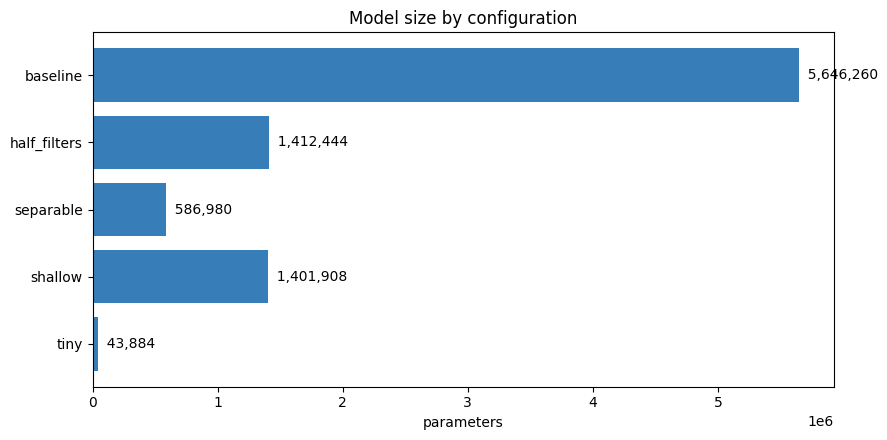

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(sizes["config"], sizes["parameters"], color="#377eb8")
ax.set_xlabel("parameters")
ax.set_title("Model size by configuration")
ax.invert_yaxis()
for i, value in enumerate(sizes["parameters"]):
    ax.text(value, i, "  {:,}".format(value), va="center", fontsize=10)
plt.tight_layout()
plt.show()

This chart compares model size only. Fewer parameters do not establish segmentation quality, peak memory use, or inference speed. The next steps measure training time and validation Dice.


## 4. Prepare patches

I use the same patient splits and patch dimensions for every configuration. The loader extracts random crops and applies rotations, flips, and brightness changes during training.

The sampled patches can differ between runs, including during validation. This pipeline follows the earlier approach, but its augmentation function is not identical to the training notebook's.


In [30]:
def extract_patch(image, mask, patch_size):
    shape = image.shape[:3]
    x = np.random.randint(0, max(shape[0] - patch_size[0], 1))
    y = np.random.randint(0, max(shape[1] - patch_size[1], 1))
    z = np.random.randint(0, max(shape[2] - patch_size[2], 1))
    return (image[x:x + patch_size[0], y:y + patch_size[1], z:z + patch_size[2], :],
            mask[x:x + patch_size[0], y:y + patch_size[1], z:z + patch_size[2]])


def augment(image, mask):
    angle = np.random.uniform(-15, 15)
    image = rotate(image, angle, axes=(0, 1), reshape=False, mode="reflect")
    mask = rotate(mask, angle, axes=(0, 1), reshape=False, mode="reflect", order=0)
    if np.random.rand() > 0.5:
        image, mask = np.flip(image, axis=0), np.flip(mask, axis=0)
    if np.random.rand() > 0.5:
        image, mask = np.flip(image, axis=1), np.flip(mask, axis=1)
    image = np.clip(image * np.random.uniform(0.9, 1.1), 0, 1)
    return image, mask


class GliomaPatches(Dataset):
    def __init__(self, img_dir, mask_dir, patch_size, is_training):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.patch_size = patch_size
        self.is_training = is_training
        self.names = sorted(f for f in os.listdir(img_dir) if f.endswith(".npy"))

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        name = self.names[index]
        image = np.load(os.path.join(self.img_dir, name)).astype(np.float32)
        mask_name = name.replace("image_", "mask_")
        mask = np.argmax(np.load(os.path.join(self.mask_dir, mask_name)), axis=-1)

        image, mask = extract_patch(image, mask, self.patch_size)
        if self.is_training:
            image, mask = augment(image, mask)

        image = np.ascontiguousarray(np.transpose(image, (3, 0, 1, 2)), dtype=np.float32)
        mask = np.ascontiguousarray(mask, dtype=np.int64)
        return torch.from_numpy(image), torch.from_numpy(mask)

In [31]:
def make_loader(split, is_training, shuffle):
    dataset = GliomaPatches(os.path.join(DATA_ROOT, split, "images"),
                            os.path.join(DATA_ROOT, split, "masks"),
                            PATCH_SIZE, is_training)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)


train_loader = make_loader("train", is_training=True, shuffle=True)
val_loader = make_loader("val", is_training=False, shuffle=False)

print("Train volumes:", len(train_loader.dataset))
print("Val volumes:  ", len(val_loader.dataset))

Train volumes: 66
Val volumes:   13


## 5. Define training and evaluation

I combine Dice loss with cross-entropy. The reported metric averages Dice over the four classes, including background. A single mean can hide missed tumor classes, so per-class scores would be useful in a more detailed evaluation.

`train_config` groups training and validation into one reusable function.


In [32]:
def dice_loss(logits, target, num_classes, smooth=1e-6):
    probs = F.softmax(logits, dim=1)
    target_onehot = F.one_hot(target, num_classes).permute(0, 4, 1, 2, 3).float()
    dims = (0, 2, 3, 4)
    intersection = torch.sum(probs * target_onehot, dims)
    cardinality = torch.sum(probs + target_onehot, dims)
    return 1 - ((2. * intersection + smooth) / (cardinality + smooth)).mean()


cross_entropy = nn.CrossEntropyLoss()


def total_loss(logits, target):
    return dice_loss(logits, target, NUM_CLASSES) + cross_entropy(logits, target)


@torch.no_grad()
def dice_score(logits, target, num_classes=NUM_CLASSES, smooth=1e-6):
    preds = torch.argmax(logits, dim=1)
    scores = []
    for c in range(num_classes):
        p = (preds == c).float()
        t = (target == c).float()
        scores.append(((2. * (p * t).sum() + smooth) / (p.sum() + t.sum() + smooth)).item())
    return float(np.mean(scores))

In [33]:
def train_config(cfg, epochs, train_loader, val_loader):
    torch.manual_seed(SEED)
    model = ConfigurableUNet(**cfg).to(device)
    optimizer = torch.optim.NAdam(model.parameters(), lr=0.001)

    start = time.time()
    for _ in range(epochs):
        model.train()
        for images, masks in train_loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss = total_loss(logits, masks)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
    train_minutes = (time.time() - start) / 60

    model.eval()
    val_scores = []
    with torch.no_grad():
        for images, masks in val_loader:
            logits = model(images.to(device))
            val_scores.append(dice_score(logits, masks.to(device)))

    return model, train_minutes, float(np.mean(val_scores))

For each configuration, `train_config` creates a new model, trains it for the requested number of epochs, and returns its training time and validation Dice.

It resets the PyTorch seed, but does not reset NumPy's generator used for crops and augmentation. The models therefore do not receive identical patches. Fixed validation patches and more complete seed control would make the comparison stronger.


## 6. Train the five variants

I start with five epochs per model to keep the experiment manageable. This gives an initial comparison, not each architecture's best achievable performance.

The loop trains the models sequentially. It records their measurements but does not save their weights, so this step does not replace the saved checkpoint from the training notebook.


In [34]:
EPOCHS = 5

results = []
for name, cfg in CONFIGS.items():
    print("Training:", name)
    _, minutes, val_dice = train_config(cfg, EPOCHS, train_loader, val_loader)
    params = count_params(ConfigurableUNet(**cfg))
    results.append({"config": name, "parameters": params,
                    "train_minutes": round(minutes, 2), "val_dice": round(val_dice, 4)})
    print("  parameters {:,}  |  {:.2f} min  |  val Dice {:.4f}".format(
        params, minutes, val_dice))

results = pd.DataFrame(results)

Training: baseline
  parameters 5,646,260  |  11.67 min  |  val Dice 0.3672
Training: half_filters
  parameters 1,412,444  |  7.43 min  |  val Dice 0.2709
Training: separable
  parameters 586,980  |  20.86 min  |  val Dice 0.4100
Training: shallow
  parameters 1,401,908  |  11.32 min  |  val Dice 0.3312
Training: tiny
  parameters 43,884  |  9.63 min  |  val Dice 0.3758


In [35]:
results["vs_baseline_size"] = (
    results["parameters"] / results.loc[0, "parameters"]).round(3)
results

,config,parameters,train_minutes,val_dice,vs_baseline_size
0,baseline,5646260,11.67,0.3672,1.000
1,half_filters,1412444,7.43,0.2709,0.250
2,separable,586980,20.86,0.4100,0.104
3,shallow,1401908,11.32,0.3312,0.248
4,tiny,43884,9.63,0.3758,0.008


## 7. Compare size and validation Dice

Each point represents one configuration. Moving left means fewer parameters; moving up means a higher measured validation Dice. I look for smaller models that retain useful performance in this experiment, while remembering that the scores come from short runs and randomly sampled patches.


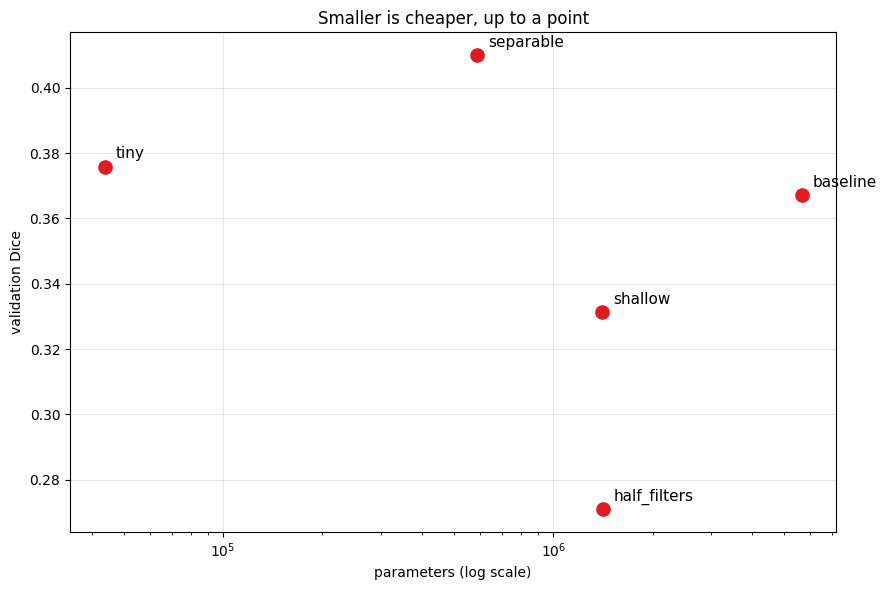

In [36]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(results["parameters"], results["val_dice"], s=90, color="#e41a1c", zorder=3)
for _, row in results.iterrows():
    ax.annotate(row["config"], (row["parameters"], row["val_dice"]),
                textcoords="offset points", xytext=(8, 6), fontsize=11)

ax.set_xscale("log")
ax.set_xlabel("parameters (log scale)")
ax.set_ylabel("validation Dice")
ax.set_title("Smaller is cheaper, up to a point")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. What I learned from this comparison

After five epochs per model, reducing the number of parameters did not produce a consistent change in validation Dice or training time.

| Configuration | Parameters | Training time | Validation Dice |
|---|---:|---:|---:|
| Baseline | 5,646,260 | 11.67 min | 0.3672 |
| Half filters | 1,412,444 | 7.43 min | 0.2709 |
| Separable | 586,980 | 20.86 min | 0.4100 |
| Shallow | 1,401,908 | 11.32 min | 0.3312 |
| Tiny | 43,884 | 9.63 min | 0.3758 |

The **separable model** achieved the highest validation Dice, with about **90% fewer parameters** than the baseline. However, it also took the longest to train. This shows that fewer parameters do not necessarily mean faster execution on the hardware used.

The **tiny model** was particularly interesting: it used about **99.2% fewer parameters** while reaching a Dice slightly above the baseline. Its training time decreased much less dramatically than its parameter count.

The **half-filter model** trained fastest but obtained the lowest Dice. The **shallow model** also reduced parameter count substantially, yet its training time remained close to the baseline and its Dice was lower.

For this initial experiment, I would investigate the tiny and separable models further: one offers a very small network, while the other achieved the highest measured Dice. These results remain preliminary because training lasted only five epochs and validation used random patches. The reported Dice also averages all four classes, including background, so it does not establish that every tumor region was segmented well.